In [17]:
import matplotlib.pyplot as plt 
import pandas as pd
from stimuli_effect_identification import dataset_simulation

In [18]:
data_measure = pd.read_csv('data/database.csv')


In [19]:
data_measure.rename(columns={'opstart': 'surgery_time'}, inplace=True)
data_measure.intubation_time = (data_measure.intubation_time - 2*60).clip(0, 6000) # from end to start of intubation
data_measure['Propofol'] = data_measure['Propofol']*20/3600
data_measure['Remifentanil'] = data_measure['Remifentanil']*20/3600
data_measure['TPR'] = (data_measure['MAP'] / (data_measure['HR'] * data_measure['SV'])).clip(0, 0.04)
data_measure = data_measure.query('split == "test"').reset_index()
# data_measure = data_measure.query('caseid < 600')

In [20]:
data_simu_stimuli = pd.read_csv('data/simulated_vitaldb_test.csv')
data_simu_no_stimuli = pd.read_csv('data/simulated_vitaldb_no_stimuli.csv')

In [21]:
data_simu_stimuli = pd.merge(data_simu_stimuli, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])
data_simu_no_stimuli = pd.merge(data_simu_no_stimuli, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])

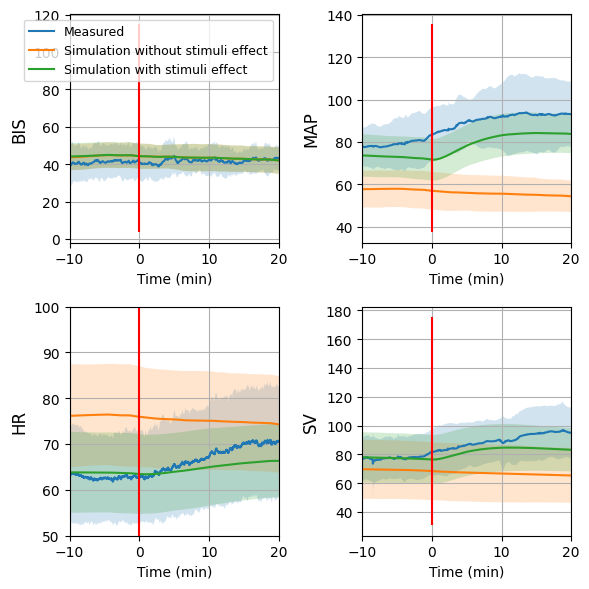

In [26]:
signal_list = ['BIS', 'MAP', 'HR', 'SV']
median_intub_time = data_simu_stimuli['intubation_time'].median()/60
median_surg_time = data_simu_stimuli['surgery_time'].median()/60

zoom = 'surgery' #surgery, intub, all


if zoom=='all':
    data_simu_stimuli['Time_aligned'] = data_simu_stimuli['Time']
    data_simu_no_stimuli['Time_aligned'] = data_simu_no_stimuli['Time']
    data_measure['Time_aligned'] = data_measure['Time']
if zoom=='intub':
    data_simu_stimuli['Time_aligned'] = data_simu_stimuli['Time'] - data_simu_stimuli['intubation_time']
    data_simu_no_stimuli['Time_aligned'] = data_simu_no_stimuli['Time'] - data_simu_no_stimuli['intubation_time']
    data_measure['Time_aligned'] = data_measure['Time'] - data_measure['intubation_time']
if zoom=='surgery':
    data_simu_stimuli['Time_aligned'] = data_simu_stimuli['Time'] - data_simu_stimuli['surgery_time']
    data_simu_no_stimuli['Time_aligned'] = data_simu_no_stimuli['Time'] - data_simu_no_stimuli['surgery_time']
    data_measure['Time_aligned'] = data_measure['Time'] - data_measure['surgery_time']

end_time_min = data_measure.groupby('caseid').Time.max().min()

plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_measure.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_measure.groupby("Time_aligned")[signal].std().reset_index()
    y_dist = data_simu_stimuli.groupby("Time_aligned")[signal].mean().reset_index()
    y_dist_std = data_simu_stimuli.groupby("Time_aligned")[signal].std().reset_index()
    y_no_stim = data_simu_no_stimuli.groupby("Time_aligned")[signal].mean().reset_index()
    y_no_stim_std = data_simu_no_stimuli.groupby("Time_aligned")[signal].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measured')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_no_stim[signal].values, label='Simulation without stimuli effect')
    plt.fill_between(x, y_no_stim[signal].values-y_no_stim_std[signal].values, y_no_stim[signal].values+y_no_stim_std[signal].values
    , alpha = 0.2)
    plt.plot(x, y_dist[signal].values, label='Simulation with stimuli effect')
    plt.fill_between(x, y_dist[signal].values-y_dist_std[signal].values, y_dist[signal].values+y_dist_std[signal].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    if zoom == 'all':
        plt.vlines(median_intub_time,y_lim[0], y_lim[1], 'g')
        plt.vlines(median_surg_time,y_lim[0], y_lim[1], 'r')
    if zoom=='intub':
        plt.vlines(0,y_lim[0], y_lim[1], 'g')
    if zoom=='surgery':
        plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
    if zoom == 'all':
        plt.xlim([0,end_time_min/60])
    if zoom == 'intub':
        plt.xlim([-5, 20])
    if zoom == 'surgery':
        plt.xlim([-10, 20])
plt.tight_layout()
plt.savefig(f'output/dist_{zoom}.pdf', dpi=300)
plt.show()

In [23]:
from example.performance_computation import compute_kpis_with_std

for signal in signal_list:
    res_no_stimuli = compute_kpis_with_std(data_measure, data_simu_no_stimuli, value_col=signal)
    res_stimuli = compute_kpis_with_std(data_measure, data_simu_stimuli, value_col=signal)

    print(f'{signal}:')
    print(pd.concat([res_no_stimuli, res_stimuli]).round(1))

/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)


BIS:
   MDPE_mean  MDPE_std  RMSE_mean  RMSE_std  MDAPE_mean  MDAPE_std  N_patients
0        2.5      18.7       10.7       3.1        18.1        9.1          30
0        3.1      18.7       10.6       3.1        17.9        9.3          30


/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)


MAP:
   MDPE_mean  MDPE_std  RMSE_mean  RMSE_std  MDAPE_mean  MDAPE_std  N_patients
0      -36.9       9.7       34.8       9.4        36.9        9.7          30
0       -6.3      12.7       16.5       5.4        14.1        5.9          30


/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)


HR:
   MDPE_mean  MDPE_std  RMSE_mean  RMSE_std  MDAPE_mean  MDAPE_std  N_patients
0        7.4      21.2       17.1       8.2        19.1       13.6          30
0       -3.1      16.3       16.2       6.8        15.5        7.9          30
SV:
   MDPE_mean  MDPE_std  RMSE_mean  RMSE_std  MDAPE_mean  MDAPE_std  N_patients
0      -23.2      24.1       30.8      13.8        29.7       17.0          30
0       -5.0      22.0       22.9       8.9        21.1       11.3          30


/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/bob/Documents/code/stimuli_effect_identification/example/performance_computation.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
